# 02 - Advanced Image Processing | معالجة الصور المتقدمة

يجمع اكتشاف الحواف والأشكال مع التقسيم والعمليات المورفولوجية وعزل العناصر. مجلدا نتائج 04 و05 الأصليان ما زالا مستخدمين كما هما.


---

## القسم المدمج: Edge & Shape Detection

> المصدر الأصلي: `04_Edge_Shape_Detection.ipynb`. تم الحفاظ على مسارات البيانات والمخرجات الأصلية، مع إعادة تسمية بعض المتغيرات/الدوال فقط لمنع التعارض داخل الدفتر الموحّد.


## 04 - اكتشاف الحواف والأشكال والنقاط المميزة

**المشروع:** Vision Studio - معالجة الصور والرؤية بالحاسوب  
**المقرر:** معالجة الصور والرؤية بالحاسوب - بكالوريوس ذكاء اصطناعي  
**إشراف:** الدكتورة سمية الشيبة

في هذا الدفتر سنحوّل موضوعات الحواف من المحاضرات إلى وظائف عملية قابلة للنقل لاحقًا إلى تطبيق Android يعمل دون إنترنت.

## أهداف الدفتر

بعد تنفيذ الدفتر ستتمكن من:

1. اكتشاف الحواف باستخدام **Sobel وLaplacian وCanny**.
2. تحسين حدة الصورة باستخدام Laplacian.
3. اكتشاف الخطوط باستخدام **Probabilistic Hough Transform**.
4. اكتشاف الدوائر باستخدام **Hough Circle Transform**.
5. اكتشاف الزوايا والنقاط المميزة باستخدام **Shi-Tomasi**.
6. مقارنة النتائج بصريًا وتغيير المعاملات تفاعليًا.
7. معالجة جميع صور المشروع وحفظ النتائج تلقائيًا في Google Drive.

> ملاحظة مهمة للإنترنت البطيء: الدفتر يعيد استخدام الصور الموجودة في Drive، ولا يرفع أي ملف إلا إذا غيّرت `UPLOAD_NEW_FILES` إلى `True`.

## 1. استيراد المكتبات وربط Google Drive

In [1]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
    PROJECT_ROOT = Path(
        '/content/drive/MyDrive/'
        'VisionStudio_Android_ImageProcessing'
    )
except ImportError:
    IN_COLAB = False
    PROJECT_ROOT = Path('VisionStudio_Android_ImageProcessing')

EDGE_INPUT_DIR = PROJECT_ROOT / '02_Data/Images/Input'
EDGE_OUTPUT_DIR = (
    PROJECT_ROOT
    / '04_Outputs/Images/04_Edge_Shape_Detection'
)

EDGE_INPUT_DIR.mkdir(parents=True, exist_ok=True)
EDGE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('Running in Colab:', IN_COLAB)
print('Input directory:', EDGE_INPUT_DIR)
print('Output directory:', EDGE_OUTPUT_DIR)

Mounted at /content/drive
Running in Colab: True
Input directory: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/02_Data/Images/Input
Output directory: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/04_Edge_Shape_Detection


## 2. دوال العرض والتحقق

يستخدم OpenCV ترتيب الألوان BGR، بينما يستخدم Matplotlib ترتيب RGB. لذلك تحول دالة `to_rgb` الصورة للعرض فقط، من دون تغيير الصورة الأصلية المستخدمة في المعالجة.

In [2]:
def edge_to_rgb(image):
    if image.ndim == 2:
        return image
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def edge_show_comparison(results, columns=3, figure_width=16):
    items = list(results.items())
    rows = int(np.ceil(len(items) / columns))
    fig, axes = plt.subplots(
        rows, columns,
        figsize=(figure_width, rows * 4.5),
        squeeze=False
    )

    for axis, (title, result) in zip(axes.ravel(), items):
        axis.imshow(
            edge_to_rgb(result),
            cmap='gray' if result.ndim == 2 else None
        )
        axis.set_title(title)
        axis.axis('off')

    for axis in axes.ravel()[len(items):]:
        axis.axis('off')

    plt.tight_layout()
    plt.show()


def valid_odd_kernel(kernel_size, minimum=1):
    kernel_size = max(int(kernel_size), int(minimum))
    if kernel_size % 2 == 0:
        kernel_size += 1
    return kernel_size


def normalize_for_display(image):
    return cv2.normalize(
        image, None, 0, 255, cv2.NORM_MINMAX
    ).astype(np.uint8)

## 3. دوال اكتشاف الحواف وتحسين الحدة

In [3]:
def sobel_edges(image, kernel_size=3):
    k = valid_odd_kernel(kernel_size, minimum=1)
    if k > 7:
        k = 7

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (3, 3), 0)
    sobel_x = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=k)
    sobel_y = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=k)
    magnitude = cv2.magnitude(
        sobel_x.astype(np.float32),
        sobel_y.astype(np.float32)
    )

    return (
        cv2.convertScaleAbs(sobel_x),
        cv2.convertScaleAbs(sobel_y),
        normalize_for_display(magnitude)
    )


def laplacian_edges(image, kernel_size=3):
    k = valid_odd_kernel(kernel_size, minimum=1)
    if k > 7:
        k = 7

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (3, 3), 0)
    laplacian = cv2.Laplacian(blurred, cv2.CV_64F, ksize=k)
    return cv2.convertScaleAbs(laplacian)


def laplacian_sharpen(image, alpha=0.5):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (3, 3), 0)
    laplacian = cv2.Laplacian(blurred, cv2.CV_64F, ksize=3)
    sharpened = gray.astype(np.float64) - float(alpha) * laplacian
    return gray, np.clip(sharpened, 0, 255).astype(np.uint8)


def canny_edges(image, low_threshold=100, high_threshold=200, blur_size=5):
    low = max(0, int(low_threshold))
    high = max(low + 1, int(high_threshold))
    k = valid_odd_kernel(blur_size, minimum=3)

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (k, k), 0)
    return cv2.Canny(blurred, low, high)

## 4. دوال اكتشاف الخطوط والدوائر والزوايا

In [4]:
def detect_lines(
    image, low_threshold=50, high_threshold=128,
    hough_threshold=30, min_line_length=50, max_line_gap=10
):
    edges = canny_edges(
        image, low_threshold, high_threshold, blur_size=5
    )
    lines = cv2.HoughLinesP(
        edges,
        rho=1,
        theta=np.pi / 180,
        threshold=int(hough_threshold),
        minLineLength=int(min_line_length),
        maxLineGap=int(max_line_gap)
    )

    result = image.copy()
    line_count = 0
    if lines is not None:
        line_points = np.asarray(lines).reshape(-1, 4)
        line_count = len(line_points)
        for x1, y1, x2, y2 in line_points:
            cv2.line(result, (x1, y1), (x2, y2), (0, 0, 255), 3)

    return result, line_count, edges


def detect_circles(
    image, dp=1.2, min_distance=40,
    param1=100, param2=30, min_radius=0, max_radius=100
):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blurred = cv2.medianBlur(gray, 5)
    circles = cv2.HoughCircles(
        blurred,
        cv2.HOUGH_GRADIENT,
        dp=float(dp),
        minDist=max(1, float(min_distance)),
        param1=float(param1),
        param2=float(param2),
        minRadius=max(0, int(min_radius)),
        maxRadius=max(0, int(max_radius))
    )

    result = image.copy()
    circle_count = 0
    if circles is not None:
        rounded_circles = np.uint16(
            np.around(np.asarray(circles).reshape(-1, 3))
        )
        circle_count = len(rounded_circles)
        for x, y, radius in rounded_circles:
            cv2.circle(result, (int(x), int(y)), int(radius), (0, 255, 0), 3)
            cv2.circle(result, (int(x), int(y)), 3, (0, 0, 255), -1)

    return result, circle_count


def detect_corners(
    image, max_corners=100, quality_level=0.01, min_distance=10
):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    corners = cv2.goodFeaturesToTrack(
        gray,
        maxCorners=max(1, int(max_corners)),
        qualityLevel=max(0.001, float(quality_level)),
        minDistance=max(1, float(min_distance))
    )

    result = image.copy()
    corner_count = 0
    if corners is not None:
        corner_points = np.int32(
            np.round(np.asarray(corners).reshape(-1, 2))
        )
        corner_count = len(corner_points)
        for x, y in corner_points:
            cv2.circle(result, (int(x), int(y)), 5, (255, 0, 255), -1)

    return result, corner_count

## 5. قراءة صور Drive أو رفع صور جديدة اختياريًا

- اترك `UPLOAD_NEW_FILES = False` في التشغيل المعتاد؛ سيقرأ الدفتر الصور التي رفعتها سابقًا.
- غيّرها إلى `True` فقط عندما تريد إضافة صور جديدة.
- يمكنك وضع اسم صورة محددة لاحقًا في `SELECTED_IMAGE_NAME`.

In [5]:
UPLOAD_NEW_FILES = False
SUPPORTED_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}


def edge_load_images_from_directory(directory):
    images = {}
    for path in sorted(directory.iterdir()):
        if not path.is_file() or path.suffix.lower() not in SUPPORTED_EXTENSIONS:
            continue
        loaded = cv2.imread(str(path), cv2.IMREAD_COLOR)
        if loaded is None:
            print(f'تعذر قراءة الملف: {path.name}')
            continue
        images[path.name] = loaded
    return images


uploaded_images = edge_load_images_from_directory(EDGE_INPUT_DIR)

if IN_COLAB and UPLOAD_NEW_FILES:
    from google.colab import files

    new_files = files.upload()
    for file_name, file_data in new_files.items():
        image_array = np.frombuffer(file_data, dtype=np.uint8)
        loaded_image = cv2.imdecode(image_array, cv2.IMREAD_COLOR)

        if loaded_image is None:
            print(f'تعذر قراءة الملف: {file_name}')
            continue

        safe_name = Path(file_name).name
        save_path = EDGE_INPUT_DIR / safe_name
        if not cv2.imwrite(str(save_path), loaded_image):
            raise IOError(f'فشل حفظ الصورة: {save_path}')
        uploaded_images[safe_name] = loaded_image

# صورة اختبار محلية تُنشأ فقط إذا كان مجلد الصور فارغًا.
if not uploaded_images:
    generated = np.full((520, 800, 3), 245, dtype=np.uint8)
    cv2.rectangle(generated, (70, 70), (350, 260), (30, 80, 180), 7)
    cv2.line(generated, (60, 440), (730, 320), (20, 20, 20), 8)
    cv2.line(generated, (410, 90), (740, 250), (180, 40, 30), 7)
    cv2.circle(generated, (540, 350), 95, (30, 150, 40), 7)
    cv2.circle(generated, (700, 110), 50, (150, 30, 150), 6)
    cv2.putText(
        generated, 'VISION', (95, 190),
        cv2.FONT_HERSHEY_SIMPLEX, 1.5, (20, 20, 20), 4, cv2.LINE_AA
    )
    generated_name = 'edge_shape_test.png'
    generated_path = EDGE_INPUT_DIR / generated_name
    if not cv2.imwrite(str(generated_path), generated):
        raise IOError(f'فشل حفظ صورة الاختبار: {generated_path}')
    uploaded_images[generated_name] = generated
    print('لم توجد صور؛ تم إنشاء صورة اختبار تلقائيًا.')

print(f'عدد الصور المتاحة: {len(uploaded_images)}')
for name, loaded_image in uploaded_images.items():
    height, width = loaded_image.shape[:2]
    print(f'- {name}: {width} x {height}')

عدد الصور المتاحة: 4
- R.jpeg: 736 x 736
- balloons.jpg: 602 x 547
- children.jpeg: 1376 x 774
- coins.jpg: 400 x 390


## 6. اختيار صورة العرض

Selected image: R.jpeg
Shape: (736, 736, 3)
Data type: uint8


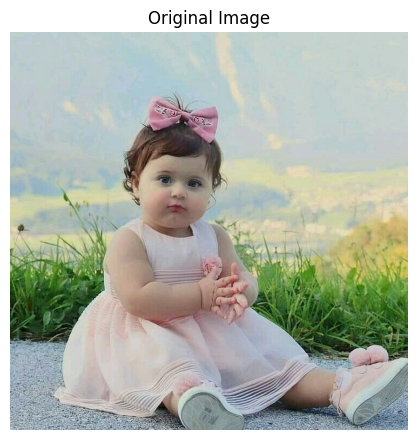

In [6]:
# اتركه فارغًا لاختيار أول صورة، أو اكتب اسم الملف كاملًا بين علامتي الاقتباس.
SELECTED_IMAGE_NAME = ''

if SELECTED_IMAGE_NAME:
    if SELECTED_IMAGE_NAME not in uploaded_images:
        available = ', '.join(uploaded_images.keys())
        raise ValueError(
            f'الصورة غير موجودة. الصور المتاحة: {available}'
        )
    selected_name = SELECTED_IMAGE_NAME
else:
    selected_name = next(iter(uploaded_images))

image = uploaded_images[selected_name]

print('Selected image:', selected_name)
print('Shape:', image.shape)
print('Data type:', image.dtype)
edge_show_comparison({'Original Image': image}, columns=1, figure_width=8)

## 7. مقارنة طرق اكتشاف الحواف

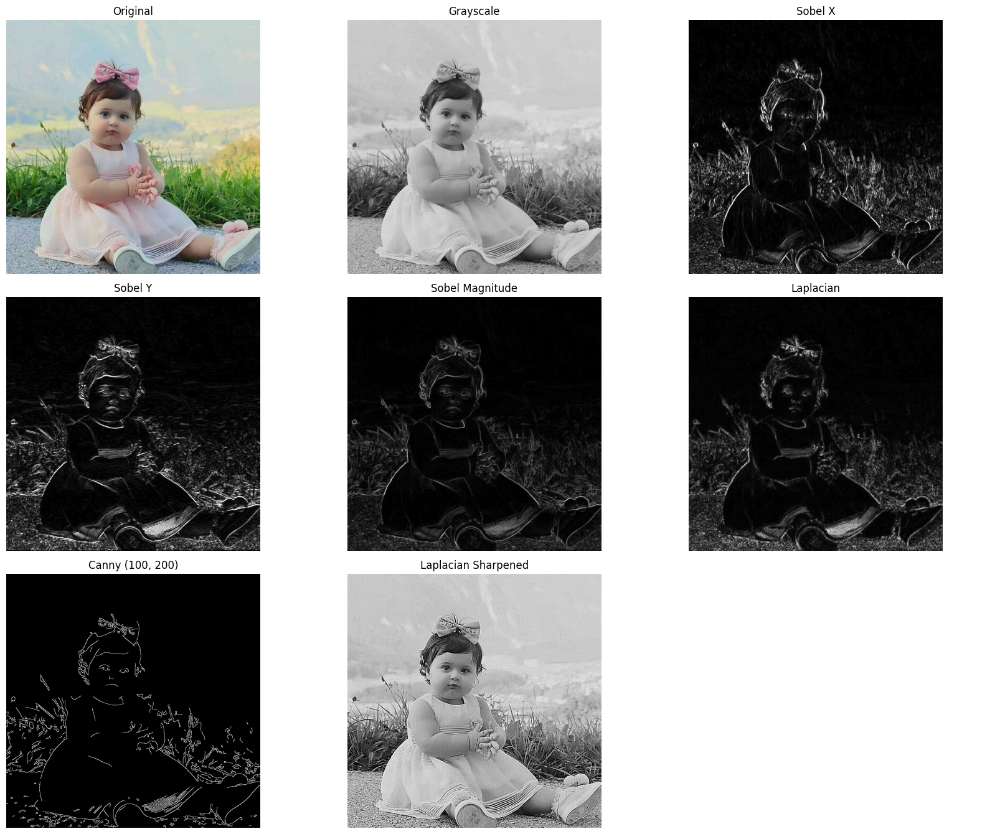

In [7]:
gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
sobel_x, sobel_y, sobel_magnitude = sobel_edges(image, kernel_size=3)
laplacian_result = laplacian_edges(image, kernel_size=3)
canny_result = canny_edges(image, 100, 200, blur_size=5)
_, laplacian_sharpened = laplacian_sharpen(image, alpha=0.5)

edge_show_comparison(
    {
        'Original': image,
        'Grayscale': gray_image,
        'Sobel X': sobel_x,
        'Sobel Y': sobel_y,
        'Sobel Magnitude': sobel_magnitude,
        'Laplacian': laplacian_result,
        'Canny (100, 200)': canny_result,
        'Laplacian Sharpened': laplacian_sharpened
    },
    columns=3,
    figure_width=17
)

### كيف نقرأ المقارنة؟

| الخوارزمية | ما الذي تبرزه؟ | ملاحظة عملية |
|---|---|---|
| Sobel X | التغير الأفقي في شدة الإضاءة، فتظهر الحواف العمودية | يمكن دمجه مع Sobel Y للحصول على مقدار الحافة |
| Sobel Y | التغير العمودي، فتظهر الحواف الأفقية | يتأثر بالضوضاء، لذلك سبقه Gaussian Blur |
| Laplacian | التغير في جميع الاتجاهات بالمشتقة الثانية | سريع لكنه حساس للضوضاء |
| Canny | حواف رفيعة ومتصلة بعد عدة مراحل | يعتمد بقوة على الحدين الأدنى والأعلى |
| Laplacian Sharpening | يعيد تفاصيل الحواف إلى الصورة | القيمة `alpha` تتحكم في قوة الحدة |

## 8. أداة Canny التفاعلية

In [8]:
try:
    import ipywidgets as widgets
    from IPython.display import display
    WIDGETS_AVAILABLE = True
except ImportError:
    WIDGETS_AVAILABLE = False
    print('الأدوات التفاعلية متاحة تلقائيًا داخل Google Colab.')


def interactive_canny(low_threshold=100, high_threshold=200, blur_size=5):
    low = int(low_threshold)
    high = max(low + 1, int(high_threshold))
    k = valid_odd_kernel(blur_size, minimum=3)
    result = canny_edges(image, low, high, k)

    edge_show_comparison(
        {
            'Original': image,
            f'Canny: low={low}, high={high}, blur={k}': result
        },
        columns=2,
        figure_width=12
    )


if WIDGETS_AVAILABLE:
    canny_controls = widgets.interactive(
        interactive_canny,
        low_threshold=widgets.IntSlider(
            value=100, min=0, max=255, step=5, description='Low'
        ),
        high_threshold=widgets.IntSlider(
            value=200, min=1, max=255, step=5, description='High'
        ),
        blur_size=widgets.IntSlider(
            value=5, min=3, max=15, step=2, description='Blur'
        )
    )
    display(canny_controls)
else:
    interactive_canny()

interactive(children=(IntSlider(value=100, description='Low', max=255, step=5), IntSlider(value=200, descripti…

## 9. اكتشاف الخطوط والدوائر والزوايا

Detected lines: 259
Detected circles: 96
Detected corners: 100


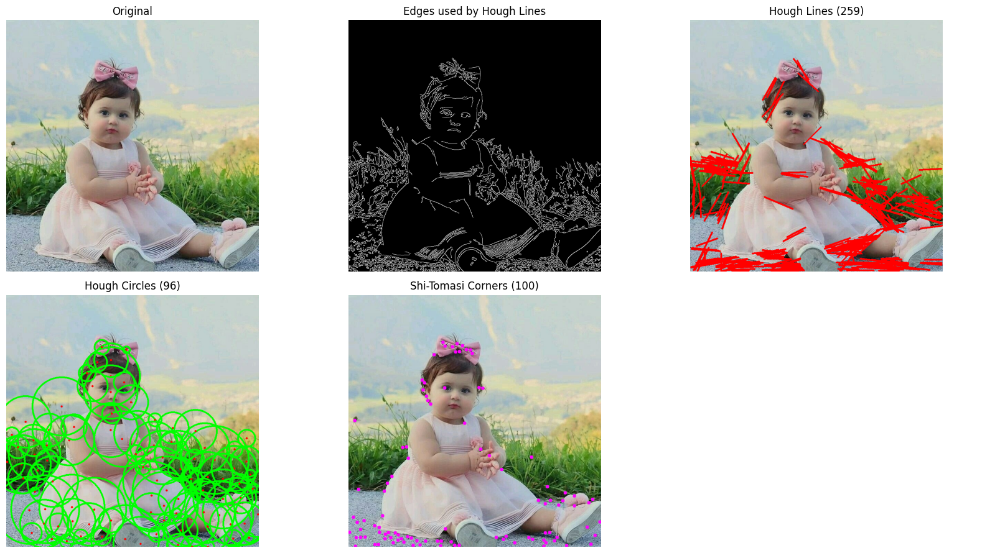

In [9]:
lines_result, line_count, line_edges = detect_lines(image)
circles_result, circle_count = detect_circles(image)
corners_result, corner_count = detect_corners(image)

print('Detected lines:', line_count)
print('Detected circles:', circle_count)
print('Detected corners:', corner_count)

edge_show_comparison(
    {
        'Original': image,
        'Edges used by Hough Lines': line_edges,
        f'Hough Lines ({line_count})': lines_result,
        f'Hough Circles ({circle_count})': circles_result,
        f'Shi-Tomasi Corners ({corner_count})': corners_result
    },
    columns=3,
    figure_width=17
)

### ماذا تعني معاملات Hough؟

- `hough_threshold`: أقل عدد من الأصوات لقبول الخط؛ زيادته تقلل الخطوط المكتشفة.
- `min_line_length`: أقصر طول مقبول للخط.
- `max_line_gap`: أكبر فجوة يسمح بربطها بين قطعتين خطيتين.
- `param2` في Hough Circles: عتبة قبول مركز الدائرة؛ خفضها يكتشف دوائر أكثر، وقد يزيد النتائج الخاطئة.
- `min_radius` و`max_radius`: نطاق نصف قطر الدوائر المتوقع.

## 10. أداة تفاعلية لاكتشاف الأشكال والنقاط

In [10]:
def interactive_detection(
    mode='Lines', sensitivity=30,
    minimum_size=40, maximum_size=120
):
    if mode == 'Lines':
        result, count, _ = detect_lines(
            image,
            hough_threshold=max(1, int(sensitivity)),
            min_line_length=max(1, int(minimum_size)),
            max_line_gap=10
        )
        title = f'Lines detected: {count}'
    elif mode == 'Circles':
        min_radius = max(0, int(minimum_size))
        max_radius = max(min_radius + 1, int(maximum_size))
        result, count = detect_circles(
            image,
            param2=max(1, int(sensitivity)),
            min_radius=min_radius,
            max_radius=max_radius
        )
        title = f'Circles detected: {count}'
    else:
        result, count = detect_corners(
            image,
            max_corners=max(1, int(maximum_size)),
            quality_level=max(0.001, float(sensitivity) / 1000.0),
            min_distance=max(1, int(minimum_size) // 4)
        )
        title = f'Corners detected: {count}'

    edge_show_comparison(
        {'Original': image, title: result},
        columns=2,
        figure_width=12
    )


if WIDGETS_AVAILABLE:
    detection_controls = widgets.interactive(
        interactive_detection,
        mode=widgets.Dropdown(
            options=['Lines', 'Circles', 'Corners'],
            value='Lines',
            description='Mode'
        ),
        sensitivity=widgets.IntSlider(
            value=30, min=5, max=100, step=1,
            description='Threshold'
        ),
        minimum_size=widgets.IntSlider(
            value=40, min=0, max=200, step=5,
            description='Minimum'
        ),
        maximum_size=widgets.IntSlider(
            value=120, min=10, max=300, step=5,
            description='Maximum'
        )
    )
    display(detection_controls)
else:
    interactive_detection()

interactive(children=(Dropdown(description='Mode', options=('Lines', 'Circles', 'Corners'), value='Lines'), In…

## 11. معالجة جميع الصور وحفظ النتائج

ستُنشأ مجلدات منفصلة لكل صورة داخل:

`04_Outputs/Images/04_Edge_Shape_Detection/اسم_الصورة/`

لن تُحذف الصور الأصلية، ولن تُستبدل ملفات الإدخال.

In [11]:
saved_files = []
processing_summary = []

for file_name, source_image in uploaded_images.items():
    stem = Path(file_name).stem
    image_output_dir = EDGE_OUTPUT_DIR / stem
    image_output_dir.mkdir(parents=True, exist_ok=True)

    source_gray = cv2.cvtColor(source_image, cv2.COLOR_BGR2GRAY)
    source_sobel_x, source_sobel_y, source_sobel_magnitude = sobel_edges(
        source_image, kernel_size=3
    )
    source_laplacian = laplacian_edges(source_image, kernel_size=3)
    source_canny = canny_edges(source_image, 100, 200, blur_size=5)
    _, source_sharpened = laplacian_sharpen(source_image, alpha=0.5)
    source_lines, source_line_count, _ = detect_lines(source_image)
    source_circles, source_circle_count = detect_circles(source_image)
    source_corners, source_corner_count = detect_corners(source_image)

    results = {
        '00_original.png': source_image,
        '01_grayscale.png': source_gray,
        '02_sobel_x.png': source_sobel_x,
        '03_sobel_y.png': source_sobel_y,
        '04_sobel_magnitude.png': source_sobel_magnitude,
        '05_laplacian.png': source_laplacian,
        '06_canny.png': source_canny,
        '07_laplacian_sharpened.png': source_sharpened,
        '08_hough_lines.png': source_lines,
        '09_hough_circles.png': source_circles,
        '10_shi_tomasi_corners.png': source_corners
    }

    for output_name, result_image in results.items():
        output_path = image_output_dir / output_name
        if not cv2.imwrite(str(output_path), result_image):
            raise IOError(f'فشل حفظ الصورة: {output_path}')
        saved_files.append(output_path)

    processing_summary.append({
        'file': file_name,
        'lines': source_line_count,
        'circles': source_circle_count,
        'corners': source_corner_count
    })

print(f'تمت معالجة {len(uploaded_images)} صورة.')
print(f'تم حفظ {len(saved_files)} ملفًا بنجاح.')
print('مجلد النتائج:', EDGE_OUTPUT_DIR)
print('\nDetection summary:')
for item in processing_summary:
    print(
        f"- {item['file']}: lines={item['lines']}, "
        f"circles={item['circles']}, corners={item['corners']}"
    )

تمت معالجة 4 صورة.
تم حفظ 44 ملفًا بنجاح.
مجلد النتائج: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/04_Edge_Shape_Detection

Detection summary:
- R.jpeg: lines=259, circles=96, corners=100
- balloons.jpg: lines=8, circles=19, corners=100
- children.jpeg: lines=321, circles=220, corners=100
- coins.jpg: lines=98, circles=24, corners=100


## 12. الربط بتطبيق Android

عند بناء نسخة Android باستخدام OpenCV، ستكون المقابلات الأساسية كالتالي:

| Python في Colab | OpenCV Android/Java | الاستخدام داخل التطبيق |
|---|---|---|
| `cv2.Sobel` | `Imgproc.Sobel` | إظهار الحواف الأفقية والعمودية |
| `cv2.Laplacian` | `Imgproc.Laplacian` | الحواف وتحسين الحدة |
| `cv2.Canny` | `Imgproc.Canny` | حواف رفيعة في الصور والفيديو المباشر |
| `cv2.HoughLinesP` | `Imgproc.HoughLinesP` | اكتشاف الخطوط ورسمها فوق الكاميرا |
| `cv2.HoughCircles` | `Imgproc.HoughCircles` | اكتشاف الدوائر |
| `cv2.goodFeaturesToTrack` | `Imgproc.goodFeaturesToTrack` | اكتشاف النقاط المميزة |

في الكاميرا المباشرة سنطبق العملية على كل إطار، لكننا سنقلل دقة إطار المعالجة عند الحاجة للمحافظة على سرعة التطبيق والعمل دون إنترنت.

## 13. أسئلة للمناقشة والتقرير

1. لماذا نستخدم Gaussian Blur قبل Canny أو Laplacian؟
2. ما الفرق بين Sobel وLaplacian من ناحية رتبة المشتقة واتجاه الحواف؟
3. ماذا يحدث عند خفض `low_threshold` و`high_threshold` في Canny كثيرًا؟
4. لماذا يحتاج Hough Lines إلى صورة حواف بدل الصورة الملونة مباشرة؟
5. كيف يؤثر `param2` على عدد الدوائر المكتشفة؟
6. جرّب صورة حقيقية تحتوي على مبانٍ أو طرق، ثم سجّل أفضل معاملات للخطوط.
7. جرّب صورة عملات أو أغطية زجاجات، ثم سجّل أفضل معاملات للدوائر.

**الخلاصة:** هذا الدفتر ينجز مرحلة الحواف والأشكال في نسخة Colab، ويهيئ نفس الوظائف لنقلها لاحقًا إلى واجهة Android والكاميرا المباشرة.

---

## القسم المدمج: Segmentation & Morphology

> المصدر الأصلي: `05_Image_Segmentation_Morphology.ipynb`. تم الحفاظ على مسارات البيانات والمخرجات الأصلية، مع إعادة تسمية بعض المتغيرات/الدوال فقط لمنع التعارض داخل الدفتر الموحّد.


## 05 - تقسيم الصور والعمليات المورفولوجية وعزل العناصر

**المشروع:** Vision Studio - معالجة الصور والرؤية بالحاسوب  
**المقرر:** معالجة الصور والرؤية بالحاسوب - بكالوريوس ذكاء اصطناعي  
**إشراف:** الدكتورة سمية الشيبة

يعتمد هذا الدفتر على موضوعات **LAB 9 - Image Segmentation** في المحاضرات، ويوسعها بوظائف عملية يحتاجها تطبيق Android مثل تنظيف الأقنعة، اكتشاف العناصر، عزل أكبر عنصر وإزالة الخلفية البسيطة.

## أهداف الدفتر

بعد تنفيذ الدفتر ستتمكن من:

1. تطبيق الأنواع الأساسية من Thresholding ومقارنتها.
2. استخدام Otsu لاختيار العتبة تلقائيًا.
3. معالجة اختلاف الإضاءة باستخدام Adaptive Thresholding.
4. عزل الألوان في فضاء HSV.
5. تقسيم ألوان الصورة باستخدام K-Means.
6. تنظيف الأقنعة باستخدام Erosion وDilation وOpening وClosing.
7. اكتشاف العناصر ورسم Contours وBounding Boxes.
8. عزل أكبر عنصر وإزالة الخلفية باستخدام GrabCut.
9. حفظ نتائج جميع الصور في Google Drive دون إعادة رفع الصور.

> لتقليل استهلاك الإنترنت، يقرأ الدفتر الصور المحفوظة سابقًا في Drive. اترك `UPLOAD_NEW_FILES = False` إلا عند إضافة صور جديدة.

## 1. استيراد المكتبات وربط Google Drive

In [1]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
    PROJECT_ROOT = Path(
        '/content/drive/MyDrive/'
        'VisionStudio_Android_ImageProcessing'
    )
except ImportError:
    IN_COLAB = False
    PROJECT_ROOT = Path('VisionStudio_Android_ImageProcessing')

SEGMENTATION_INPUT_DIR = PROJECT_ROOT / '02_Data/Images/Input'
SEGMENTATION_OUTPUT_DIR = (
    PROJECT_ROOT
    / '04_Outputs/Images/05_Image_Segmentation_Morphology'
)

SEGMENTATION_INPUT_DIR.mkdir(parents=True, exist_ok=True)
SEGMENTATION_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('Running in Colab:', IN_COLAB)
print('Input directory:', SEGMENTATION_INPUT_DIR)
print('Output directory:', SEGMENTATION_OUTPUT_DIR)

Mounted at /content/drive
Running in Colab: True
Input directory: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/02_Data/Images/Input
Output directory: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/05_Image_Segmentation_Morphology


## 2. دوال العرض والتحقق

In [2]:
def seg_to_rgb(image):
    if image.ndim == 2:
        return image
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def seg_show_comparison(results, columns=3, figure_width=16):
    items = list(results.items())
    rows = int(np.ceil(len(items) / columns))
    fig, axes = plt.subplots(
        rows, columns,
        figsize=(figure_width, rows * 4.5),
        squeeze=False
    )

    for axis, (title, result) in zip(axes.ravel(), items):
        axis.imshow(
            seg_to_rgb(result),
            cmap='gray' if result.ndim == 2 else None
        )
        axis.set_title(title)
        axis.axis('off')

    for axis in axes.ravel()[len(items):]:
        axis.axis('off')

    plt.tight_layout()
    plt.show()


def valid_odd_number(value, minimum=3):
    value = max(int(value), int(minimum))
    if value % 2 == 0:
        value += 1
    return value


def create_structuring_element(kernel_size=5, shape='ellipse'):
    k = valid_odd_number(kernel_size, minimum=1)
    shapes = {
        'rectangle': cv2.MORPH_RECT,
        'ellipse': cv2.MORPH_ELLIPSE,
        'cross': cv2.MORPH_CROSS
    }
    return cv2.getStructuringElement(shapes.get(shape, cv2.MORPH_ELLIPSE), (k, k))

## 3. دوال Thresholding والتقسيم

In [3]:
def threshold_variants(image, threshold_value=127):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    threshold_value = int(np.clip(threshold_value, 0, 255))

    variants = {'Grayscale': gray}
    threshold_types = {
        'Binary': cv2.THRESH_BINARY,
        'Binary Inverse': cv2.THRESH_BINARY_INV,
        'Truncate': cv2.THRESH_TRUNC,
        'To Zero': cv2.THRESH_TOZERO,
        'To Zero Inverse': cv2.THRESH_TOZERO_INV
    }

    for name, threshold_type in threshold_types.items():
        _, result = cv2.threshold(
            gray, threshold_value, 255, threshold_type
        )
        variants[name] = result

    return variants


def otsu_threshold(image, invert=False):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    threshold_type = cv2.THRESH_BINARY_INV if invert else cv2.THRESH_BINARY
    otsu_value, result = cv2.threshold(
        gray, 0, 255, threshold_type + cv2.THRESH_OTSU
    )
    return otsu_value, result


def adaptive_thresholds(image, block_size=11, constant=2):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    block = valid_odd_number(block_size, minimum=3)
    blurred = cv2.GaussianBlur(gray, (3, 3), 0)

    adaptive_mean = cv2.adaptiveThreshold(
        blurred, 255,
        cv2.ADAPTIVE_THRESH_MEAN_C,
        cv2.THRESH_BINARY,
        block, float(constant)
    )
    adaptive_gaussian = cv2.adaptiveThreshold(
        blurred, 255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY,
        block, float(constant)
    )
    return adaptive_mean, adaptive_gaussian


def hsv_color_mask(
    image,
    lower_hsv=(0, 70, 50),
    upper_hsv=(20, 255, 255)
):
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    lower = np.array(lower_hsv, dtype=np.uint8)
    upper = np.array(upper_hsv, dtype=np.uint8)
    mask = cv2.inRange(hsv, lower, upper)
    result = cv2.bitwise_and(image, image, mask=mask)
    return mask, result


def kmeans_segmentation(image, clusters=3, max_pixels=350000):
    clusters = max(2, int(clusters))
    height, width = image.shape[:2]
    pixel_count = height * width

    if pixel_count > max_pixels:
        scale = np.sqrt(max_pixels / pixel_count)
        work_image = cv2.resize(
            image, None, fx=scale, fy=scale,
            interpolation=cv2.INTER_AREA
        )
    else:
        work_image = image.copy()

    pixels = np.float32(work_image.reshape((-1, 3)))
    criteria = (
        cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER,
        20,
        1.0
    )
    cv2.setRNGSeed(42)
    _, labels, centers = cv2.kmeans(
        pixels, clusters, None, criteria, 5,
        cv2.KMEANS_PP_CENTERS
    )

    centers = np.uint8(centers)
    segmented_small = centers[labels.flatten()].reshape(work_image.shape)

    if segmented_small.shape[:2] != (height, width):
        return cv2.resize(
            segmented_small, (width, height),
            interpolation=cv2.INTER_NEAREST
        )
    return segmented_small

## 4. دوال العمليات المورفولوجية واكتشاف العناصر

In [4]:
def prepare_foreground_mask(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    _, mask = cv2.threshold(
        blurred, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # نجعل الجزء الأقل مساحة هو المقدمة غالبًا، لمنع الخلفية من أن تصبح عنصرًا.
    if cv2.countNonZero(mask) > mask.size / 2:
        mask = cv2.bitwise_not(mask)

    kernel = create_structuring_element(5, 'ellipse')
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    return mask


def morphology_results(mask, kernel_size=5, iterations=1, shape='ellipse'):
    kernel = create_structuring_element(kernel_size, shape)
    iterations = max(1, int(iterations))
    return {
        'Erosion': cv2.erode(mask, kernel, iterations=iterations),
        'Dilation': cv2.dilate(mask, kernel, iterations=iterations),
        'Opening': cv2.morphologyEx(
            mask, cv2.MORPH_OPEN, kernel, iterations=iterations
        ),
        'Closing': cv2.morphologyEx(
            mask, cv2.MORPH_CLOSE, kernel, iterations=iterations
        ),
        'Morphological Gradient': cv2.morphologyEx(
            mask, cv2.MORPH_GRADIENT, kernel, iterations=iterations
        )
    }


def detect_contours(image, mask=None, minimum_area=500):
    if mask is None:
        mask = prepare_foreground_mask(image)

    contours, _ = cv2.findContours(
        mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    valid_contours = [
        contour for contour in contours
        if cv2.contourArea(contour) >= float(minimum_area)
    ]

    result = image.copy()
    cv2.drawContours(result, valid_contours, -1, (0, 255, 0), 2)
    for index, contour in enumerate(valid_contours, start=1):
        x, y, width, height = cv2.boundingRect(contour)
        cv2.rectangle(
            result, (x, y), (x + width, y + height),
            (0, 0, 255), 2
        )
        cv2.putText(
            result, str(index), (x, max(20, y - 8)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.6,
            (255, 0, 0), 2, cv2.LINE_AA
        )

    return result, len(valid_contours), mask, valid_contours


def isolate_largest_object(image, mask=None):
    if mask is None:
        mask = prepare_foreground_mask(image)

    contours, _ = cv2.findContours(
        mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    if not contours:
        return np.zeros_like(image), np.zeros_like(mask), 0.0

    largest = max(contours, key=cv2.contourArea)
    object_mask = np.zeros_like(mask)
    cv2.drawContours(object_mask, [largest], -1, 255, thickness=-1)
    isolated = cv2.bitwise_and(image, image, mask=object_mask)
    return isolated, object_mask, float(cv2.contourArea(largest))


def grabcut_foreground(image, margin_ratio=0.05, iterations=3):
    height, width = image.shape[:2]
    margin_x = max(1, int(width * float(margin_ratio)))
    margin_y = max(1, int(height * float(margin_ratio)))
    rect_width = max(1, width - 2 * margin_x)
    rect_height = max(1, height - 2 * margin_y)
    rectangle = (margin_x, margin_y, rect_width, rect_height)

    grabcut_mask = np.zeros((height, width), dtype=np.uint8)
    background_model = np.zeros((1, 65), dtype=np.float64)
    foreground_model = np.zeros((1, 65), dtype=np.float64)

    cv2.grabCut(
        image, grabcut_mask, rectangle,
        background_model, foreground_model,
        max(1, int(iterations)), cv2.GC_INIT_WITH_RECT
    )

    foreground_mask = np.where(
        (grabcut_mask == cv2.GC_FGD)
        | (grabcut_mask == cv2.GC_PR_FGD),
        255, 0
    ).astype(np.uint8)
    foreground = cv2.bitwise_and(image, image, mask=foreground_mask)
    return foreground, foreground_mask

## 5. قراءة الصور الموجودة أو رفع صور جديدة اختياريًا

- التشغيل المعتاد: اترك `UPLOAD_NEW_FILES = False`.
- لإضافة صورة جديدة فقط: غيّرها مؤقتًا إلى `True`، نفّذ الخلية، ثم أعدها إلى `False`.
- إذا كان المجلد فارغًا، ينشئ الدفتر صورة اختبار صغيرة تلقائيًا.

In [5]:
UPLOAD_NEW_FILES = False
SUPPORTED_EXTENSIONS = {
    '.jpg', '.jpeg', '.png', '.bmp',
    '.tif', '.tiff', '.webp'
}


def seg_load_images_from_directory(directory):
    images = {}
    for path in sorted(directory.iterdir()):
        if not path.is_file() or path.suffix.lower() not in SUPPORTED_EXTENSIONS:
            continue
        loaded = cv2.imread(str(path), cv2.IMREAD_COLOR)
        if loaded is None:
            print(f'تعذر قراءة الملف: {path.name}')
            continue
        images[path.name] = loaded
    return images


uploaded_images = seg_load_images_from_directory(SEGMENTATION_INPUT_DIR)

if IN_COLAB and UPLOAD_NEW_FILES:
    from google.colab import files

    new_files = files.upload()
    for file_name, file_data in new_files.items():
        image_array = np.frombuffer(file_data, dtype=np.uint8)
        loaded_image = cv2.imdecode(image_array, cv2.IMREAD_COLOR)

        if loaded_image is None:
            print(f'تعذر قراءة الملف: {file_name}')
            continue

        safe_name = Path(file_name).name
        save_path = SEGMENTATION_INPUT_DIR / safe_name
        if not cv2.imwrite(str(save_path), loaded_image):
            raise IOError(f'فشل حفظ الصورة: {save_path}')
        uploaded_images[safe_name] = loaded_image

if not uploaded_images:
    height, width = 520, 800
    generated = np.full((height, width, 3), 235, dtype=np.uint8)
    illumination = np.tile(
        np.linspace(0, 45, width, dtype=np.uint8),
        (height, 1)
    )
    generated = cv2.subtract(
        generated, cv2.merge([illumination] * 3)
    )
    cv2.circle(generated, (180, 180), 95, (30, 30, 220), -1)
    cv2.rectangle(generated, (350, 80), (650, 260), (40, 190, 40), -1)
    triangle = np.array([[300, 430], [470, 300], [610, 450]], np.int32)
    cv2.fillPoly(generated, [triangle], (220, 80, 30))
    cv2.putText(
        generated, 'SEGMENT', (70, 490),
        cv2.FONT_HERSHEY_SIMPLEX, 1.2,
        (40, 40, 40), 3, cv2.LINE_AA
    )
    generated_name = 'segmentation_test.png'
    generated_path = SEGMENTATION_INPUT_DIR / generated_name
    if not cv2.imwrite(str(generated_path), generated):
        raise IOError(f'فشل حفظ صورة الاختبار: {generated_path}')
    uploaded_images[generated_name] = generated
    print('لم توجد صور؛ تم إنشاء صورة اختبار تلقائيًا.')

print(f'عدد الصور المتاحة: {len(uploaded_images)}')
for name, loaded_image in uploaded_images.items():
    image_height, image_width = loaded_image.shape[:2]
    print(f'- {name}: {image_width} x {image_height}')

عدد الصور المتاحة: 4
- R.jpeg: 736 x 736
- balloons.jpg: 602 x 547
- children.jpeg: 1376 x 774
- coins.jpg: 400 x 390


## 6. اختيار صورة العرض

Selected image: R.jpeg
Shape: (736, 736, 3)
Data type: uint8


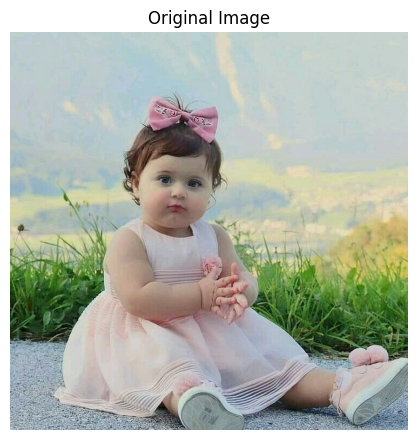

In [6]:
# اتركه فارغًا لاختيار أول صورة، أو اكتب اسم الملف كاملًا.
SELECTED_IMAGE_NAME = ''

if SELECTED_IMAGE_NAME:
    if SELECTED_IMAGE_NAME not in uploaded_images:
        available = ', '.join(uploaded_images.keys())
        raise ValueError(
            f'الصورة غير موجودة. الصور المتاحة: {available}'
        )
    selected_name = SELECTED_IMAGE_NAME
else:
    selected_name = next(iter(uploaded_images))

image = uploaded_images[selected_name]

print('Selected image:', selected_name)
print('Shape:', image.shape)
print('Data type:', image.dtype)
seg_show_comparison({'Original Image': image}, columns=1, figure_width=8)

## 7. مقارنة أنواع Thresholding

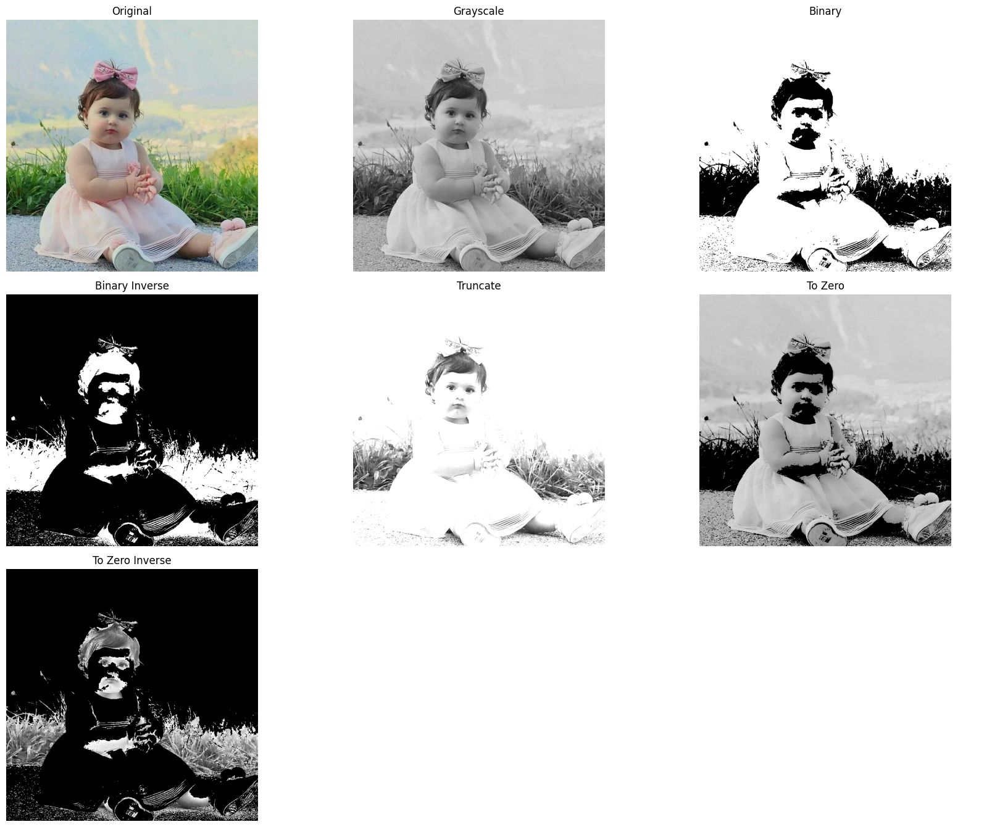

In [7]:
threshold_results = {'Original': image}
threshold_results.update(threshold_variants(image, threshold_value=127))

seg_show_comparison(
    threshold_results,
    columns=3,
    figure_width=17
)

### الفرق بين طرق Thresholding

| النوع | النتيجة |
|---|---|
| Binary | القيم الأكبر من العتبة تصبح 255 والباقي 0 |
| Binary Inverse | عكس Binary |
| Truncate | القيم الأكبر من العتبة تُستبدل بقيمة العتبة |
| To Zero | القيم الأقل من العتبة تصبح صفرًا |
| To Zero Inverse | القيم الأعلى من العتبة تصبح صفرًا |

العتبة الواحدة مناسبة عندما تكون الإضاءة متقاربة. أما الصور ذات الإضاءة غير المتساوية فتستفيد عادة من Adaptive Thresholding.

## 8. مقارنة العتبة العادية وOtsu وAdaptive Thresholding

Otsu selected threshold: 143.00


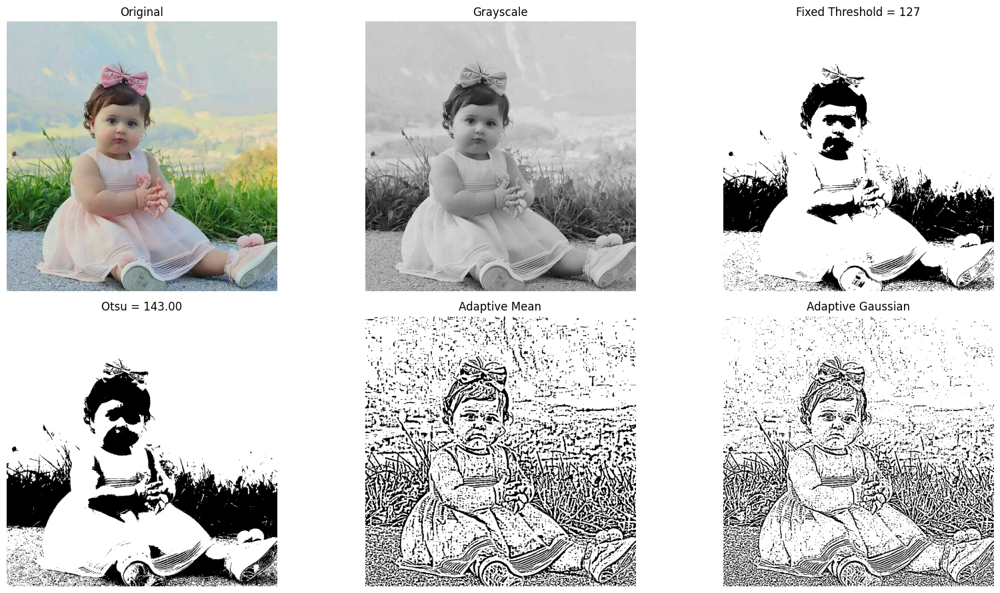

In [8]:
gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
_, fixed_binary = cv2.threshold(gray_image, 127, 255, cv2.THRESH_BINARY)
otsu_value, otsu_result = otsu_threshold(image)
adaptive_mean, adaptive_gaussian = adaptive_thresholds(
    image, block_size=11, constant=2
)

print(f'Otsu selected threshold: {otsu_value:.2f}')

seg_show_comparison(
    {
        'Original': image,
        'Grayscale': gray_image,
        'Fixed Threshold = 127': fixed_binary,
        f'Otsu = {otsu_value:.2f}': otsu_result,
        'Adaptive Mean': adaptive_mean,
        'Adaptive Gaussian': adaptive_gaussian
    },
    columns=3,
    figure_width=17
)

## 9. أداة Thresholding التفاعلية

In [9]:
try:
    import ipywidgets as widgets
    from IPython.display import display
    WIDGETS_AVAILABLE = True
except ImportError:
    WIDGETS_AVAILABLE = False
    print('الأدوات التفاعلية متاحة تلقائيًا داخل Google Colab.')


def interactive_threshold(
    method='Fixed Binary', threshold_value=127,
    block_size=11, constant=2
):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    if method == 'Fixed Binary':
        _, result = cv2.threshold(
            gray, int(threshold_value), 255, cv2.THRESH_BINARY
        )
        title = f'Fixed Threshold = {int(threshold_value)}'
    elif method == 'Otsu':
        selected_value, result = otsu_threshold(image)
        title = f'Otsu Threshold = {selected_value:.2f}'
    else:
        mean_result, gaussian_result = adaptive_thresholds(
            image, block_size, constant
        )
        if method == 'Adaptive Mean':
            result = mean_result
        else:
            result = gaussian_result
        title = (
            f'{method}: block={valid_odd_number(block_size)}, '
            f'C={constant}'
        )

    seg_show_comparison(
        {'Original': image, title: result},
        columns=2,
        figure_width=12
    )


if WIDGETS_AVAILABLE:
    threshold_controls = widgets.interactive(
        interactive_threshold,
        method=widgets.Dropdown(
            options=[
                'Fixed Binary', 'Otsu',
                'Adaptive Mean', 'Adaptive Gaussian'
            ],
            value='Fixed Binary', description='Method'
        ),
        threshold_value=widgets.IntSlider(
            value=127, min=0, max=255, step=1,
            description='Threshold'
        ),
        block_size=widgets.IntSlider(
            value=11, min=3, max=51, step=2,
            description='Block'
        ),
        constant=widgets.IntSlider(
            value=2, min=-20, max=20, step=1,
            description='C'
        )
    )
    display(threshold_controls)
else:
    interactive_threshold()

interactive(children=(Dropdown(description='Method', options=('Fixed Binary', 'Otsu', 'Adaptive Mean', 'Adapti…

## 10. عزل الألوان باستخدام HSV وتقسيم K-Means

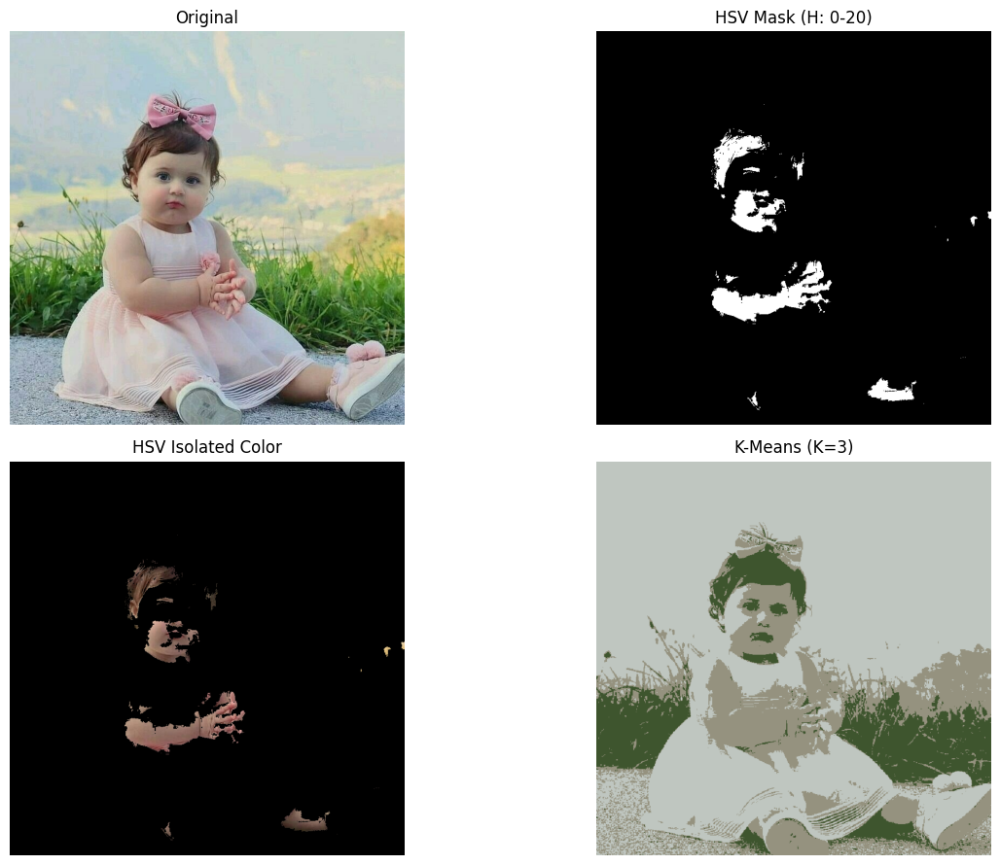

In [10]:
hsv_mask, hsv_isolated = hsv_color_mask(
    image,
    lower_hsv=(0, 70, 50),
    upper_hsv=(20, 255, 255)
)
kmeans_result = kmeans_segmentation(image, clusters=3)

seg_show_comparison(
    {
        'Original': image,
        'HSV Mask (H: 0-20)': hsv_mask,
        'HSV Isolated Color': hsv_isolated,
        'K-Means (K=3)': kmeans_result
    },
    columns=2,
    figure_width=14
)

### لماذا نستخدم HSV؟

في BGR تكون معلومات اللون والإضاءة مختلطة. في HSV يمكن تحديد:

- `H`: نوع اللون من 0 إلى 179 في OpenCV.
- `S`: تشبع اللون من 0 إلى 255.
- `V`: شدة الإضاءة من 0 إلى 255.

أما K-Means فيجمع البكسلات ذات الألوان المتقاربة في `K` مجموعات، ولا يحتاج إلى تحديد لون مسبقًا.

## 11. أداة HSV وK-Means التفاعلية

In [11]:
def interactive_color_segmentation(
    method='HSV', h_low=0, h_high=20,
    s_low=70, v_low=50, clusters=3
):
    if method == 'HSV':
        low_h = min(int(h_low), int(h_high))
        high_h = max(int(h_low), int(h_high))
        mask, result = hsv_color_mask(
            image,
            lower_hsv=(low_h, int(s_low), int(v_low)),
            upper_hsv=(high_h, 255, 255)
        )
        results = {
            'Original': image,
            f'HSV Mask H={low_h}-{high_h}': mask,
            'Isolated Color': result
        }
    else:
        result = kmeans_segmentation(image, clusters=int(clusters))
        results = {
            'Original': image,
            f'K-Means K={int(clusters)}': result
        }

    seg_show_comparison(results, columns=len(results), figure_width=15)


if WIDGETS_AVAILABLE:
    color_controls = widgets.interactive(
        interactive_color_segmentation,
        method=widgets.Dropdown(
            options=['HSV', 'K-Means'],
            value='HSV', description='Method'
        ),
        h_low=widgets.IntSlider(
            value=0, min=0, max=179, step=1, description='H Low'
        ),
        h_high=widgets.IntSlider(
            value=20, min=0, max=179, step=1, description='H High'
        ),
        s_low=widgets.IntSlider(
            value=70, min=0, max=255, step=5, description='S Low'
        ),
        v_low=widgets.IntSlider(
            value=50, min=0, max=255, step=5, description='V Low'
        ),
        clusters=widgets.IntSlider(
            value=3, min=2, max=8, step=1, description='K'
        )
    )
    display(color_controls)
else:
    interactive_color_segmentation()

interactive(children=(Dropdown(description='Method', options=('HSV', 'K-Means'), value='HSV'), IntSlider(value…

## 12. العمليات المورفولوجية

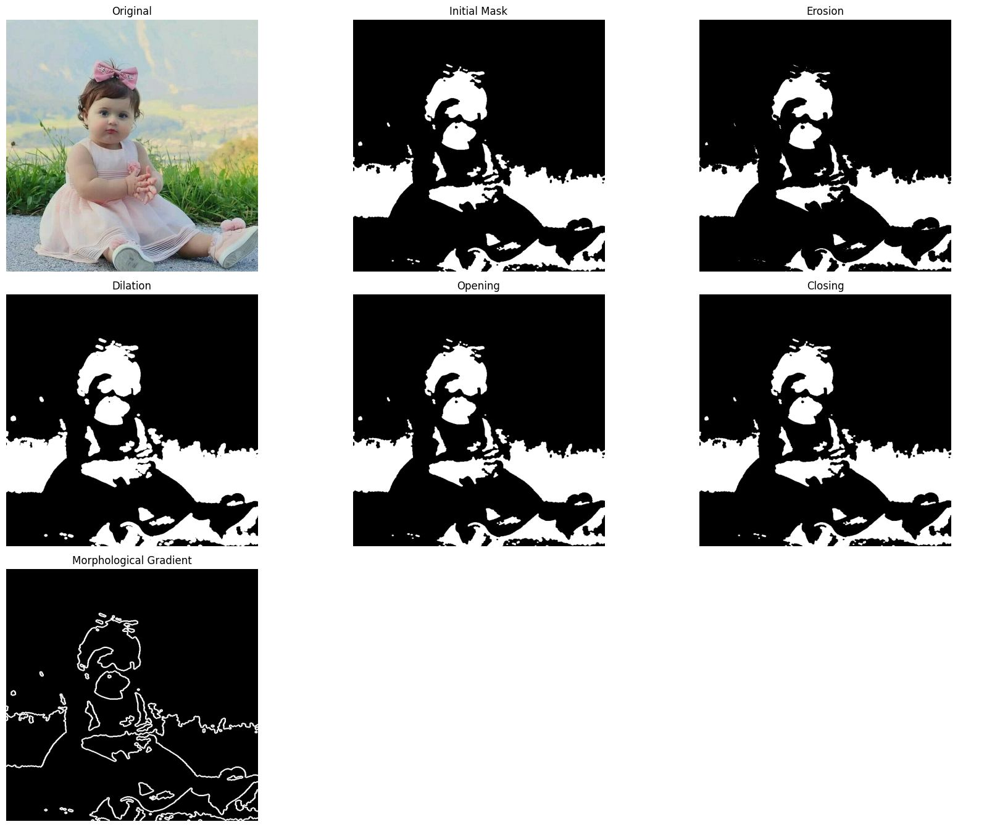

In [12]:
foreground_mask = prepare_foreground_mask(image)
morphology = morphology_results(
    foreground_mask,
    kernel_size=5,
    iterations=1,
    shape='ellipse'
)

morphology_display = {
    'Original': image,
    'Initial Mask': foreground_mask
}
morphology_display.update(morphology)

seg_show_comparison(
    morphology_display,
    columns=3,
    figure_width=17
)

### وظيفة كل عملية مورفولوجية

| العملية | الاستخدام العملي |
|---|---|
| Erosion | تقليص المناطق البيضاء وفصل العناصر المتلامسة |
| Dilation | توسيع المناطق البيضاء وربط الأجزاء القريبة |
| Opening | إزالة النقاط البيضاء الصغيرة: Erosion ثم Dilation |
| Closing | سد الثقوب والفجوات الصغيرة: Dilation ثم Erosion |
| Gradient | استخراج حدود المناطق البيضاء |

الجزء الأبيض في القناع هو العنصر الذي تتم معالجته، والأسود هو الخلفية.

## 13. اكتشاف العناصر وعزل أكبر عنصر وإزالة الخلفية

Detected objects: 10
Largest object area: 45658.50 pixels


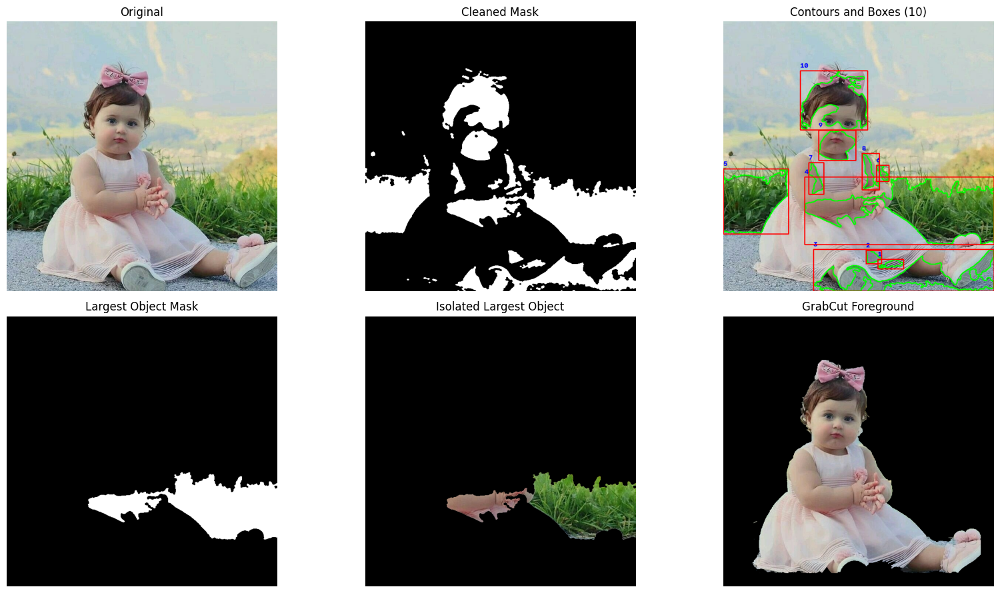

In [13]:
contour_result, object_count, cleaned_mask, contours = detect_contours(
    image, minimum_area=500
)
largest_object, largest_mask, largest_area = isolate_largest_object(
    image, cleaned_mask
)

try:
    grabcut_result, grabcut_mask = grabcut_foreground(
        image, margin_ratio=0.05, iterations=3
    )
    grabcut_status = 'GrabCut Foreground'
except cv2.error as error:
    grabcut_result = np.zeros_like(image)
    grabcut_mask = np.zeros(image.shape[:2], dtype=np.uint8)
    grabcut_status = 'GrabCut could not separate foreground'
    print('GrabCut warning:', error)

print('Detected objects:', object_count)
print(f'Largest object area: {largest_area:.2f} pixels')

seg_show_comparison(
    {
        'Original': image,
        'Cleaned Mask': cleaned_mask,
        f'Contours and Boxes ({object_count})': contour_result,
        'Largest Object Mask': largest_mask,
        'Isolated Largest Object': largest_object,
        grabcut_status: grabcut_result
    },
    columns=3,
    figure_width=17
)

## 14. معالجة جميع الصور وحفظ النتائج

ستُحفظ كل صورة في مجلد مستقل داخل:

`04_Outputs/Images/05_Image_Segmentation_Morphology/اسم_الصورة/`

الصور الأصلية لا تُحذف ولا تُعدّل.

In [14]:
saved_files = []
processing_summary = []

for file_name, source_image in uploaded_images.items():
    stem = Path(file_name).stem
    image_output_dir = SEGMENTATION_OUTPUT_DIR / stem
    image_output_dir.mkdir(parents=True, exist_ok=True)

    source_gray = cv2.cvtColor(source_image, cv2.COLOR_BGR2GRAY)
    source_variants = threshold_variants(source_image, 127)
    source_otsu_value, source_otsu = otsu_threshold(source_image)
    source_adaptive_mean, source_adaptive_gaussian = adaptive_thresholds(
        source_image, 11, 2
    )
    source_hsv_mask, source_hsv_result = hsv_color_mask(source_image)
    source_kmeans = kmeans_segmentation(source_image, clusters=3)
    source_foreground_mask = prepare_foreground_mask(source_image)
    source_morphology = morphology_results(source_foreground_mask, 5, 1)
    source_contours, source_object_count, _, _ = detect_contours(
        source_image, source_foreground_mask, minimum_area=500
    )
    source_largest, source_largest_mask, source_largest_area = (
        isolate_largest_object(source_image, source_foreground_mask)
    )

    try:
        source_grabcut, source_grabcut_mask = grabcut_foreground(
            source_image, 0.05, 3
        )
    except cv2.error:
        source_grabcut = np.zeros_like(source_image)
        source_grabcut_mask = np.zeros(
            source_image.shape[:2], dtype=np.uint8
        )

    results = {
        '00_original.png': source_image,
        '01_grayscale.png': source_gray,
        '02_binary.png': source_variants['Binary'],
        '03_binary_inverse.png': source_variants['Binary Inverse'],
        '04_otsu.png': source_otsu,
        '05_adaptive_mean.png': source_adaptive_mean,
        '06_adaptive_gaussian.png': source_adaptive_gaussian,
        '07_hsv_mask.png': source_hsv_mask,
        '08_hsv_isolated.png': source_hsv_result,
        '09_kmeans_k3.png': source_kmeans,
        '10_foreground_mask.png': source_foreground_mask,
        '11_erosion.png': source_morphology['Erosion'],
        '12_dilation.png': source_morphology['Dilation'],
        '13_opening.png': source_morphology['Opening'],
        '14_closing.png': source_morphology['Closing'],
        '15_morphological_gradient.png': (
            source_morphology['Morphological Gradient']
        ),
        '16_contours_boxes.png': source_contours,
        '17_largest_object_mask.png': source_largest_mask,
        '18_largest_object.png': source_largest,
        '19_grabcut_mask.png': source_grabcut_mask,
        '20_grabcut_foreground.png': source_grabcut
    }

    for output_name, result_image in results.items():
        output_path = image_output_dir / output_name
        if not cv2.imwrite(str(output_path), result_image):
            raise IOError(f'فشل حفظ الصورة: {output_path}')
        saved_files.append(output_path)

    processing_summary.append({
        'file': file_name,
        'otsu': source_otsu_value,
        'objects': source_object_count,
        'largest_area': source_largest_area
    })

print(f'تمت معالجة {len(uploaded_images)} صورة.')
print(f'تم حفظ {len(saved_files)} ملفًا بنجاح.')
print('مجلد النتائج:', SEGMENTATION_OUTPUT_DIR)
print('\nProcessing summary:')
for item in processing_summary:
    print(
        f"- {item['file']}: Otsu={item['otsu']:.2f}, "
        f"objects={item['objects']}, "
        f"largest area={item['largest_area']:.2f}"
    )

تمت معالجة 4 صورة.
تم حفظ 84 ملفًا بنجاح.
مجلد النتائج: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/05_Image_Segmentation_Morphology

Processing summary:
- R.jpeg: Otsu=143.00, objects=10, largest area=45658.50
- balloons.jpg: Otsu=141.00, objects=1, largest area=155597.00
- children.jpeg: Otsu=114.00, objects=13, largest area=357616.00
- coins.jpg: Otsu=157.00, objects=7, largest area=12317.00


## 15. الربط بتطبيق Android

| Python في Colab | OpenCV Android/Java | الاستخدام في التطبيق |
|---|---|---|
| `cv2.threshold` | `Imgproc.threshold` | العتبة العادية وOtsu |
| `cv2.adaptiveThreshold` | `Imgproc.adaptiveThreshold` | معالجة اختلاف الإضاءة |
| `cv2.inRange` | `Core.inRange` | إنشاء قناع HSV لعزل لون |
| `cv2.kmeans` | `Core.kmeans` | تقسيم الصورة إلى مجموعات لونية |
| `cv2.erode` | `Imgproc.erode` | تقليص القناع |
| `cv2.dilate` | `Imgproc.dilate` | توسيع القناع |
| `cv2.morphologyEx` | `Imgproc.morphologyEx` | Opening وClosing وGradient |
| `cv2.findContours` | `Imgproc.findContours` | اكتشاف العناصر |
| `cv2.boundingRect` | `Imgproc.boundingRect` | رسم صندوق حول العنصر |
| `cv2.grabCut` | `Imgproc.grabCut` | عزل مقدمة الصورة |

كل هذه العمليات محلية ويمكن تشغيلها داخل تطبيق Android دون اتصال بالإنترنت.

## 16. أسئلة للمناقشة والتقرير

1. لماذا قد تفشل العتبة الثابتة عندما تكون الإضاءة غير متساوية؟
2. كيف يختار Otsu قيمة العتبة تلقائيًا؟
3. ما الفرق بين Opening وClosing؟
4. لماذا يكون HSV أنسب من BGR لعزل لون محدد؟
5. ماذا يحدث عند زيادة قيمة `K` في K-Means؟
6. كيف يؤثر `minimum_area` على عدد العناصر المكتشفة؟
7. ما الفرق بين العزل بالقناع اللوني والعزل باستخدام GrabCut؟

> بعد التأكد من حفظ النتائج، يمكن استخدام `Edit → Clear all outputs` قبل إغلاق الدفتر لتقليل حجمه وتسريع حفظه مع الإنترنت البطيء.

**الخطوة التالية:** الدفتر `06_Video_Processing.ipynb` لمعالجة الفيديو إطارًا بإطار وحفظ الفيديو الناتج.